In [1]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")
validation = pd.read_csv("../data/validation.csv")
test = pd.read_csv("../data/test.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

display(train.head())

Train: (11089, 2)
Validation: (2101, 2)
Test: (2101, 2)


,text,label
0,Can you explain the event loop in Node.js?,0
1,Instructions to ignore: none. New instructions...,1
2,What is the tallest waterfall in the world,0
3,How is chocolate made from cacao,0
4,What is the difference between annual and pere...,0


In [2]:
print("Типы данных:")
print(train.dtypes)

print("\nПропущенные значения:")
print(train.isnull().sum())

print("\nДубликаты:")
print(train.duplicated().sum())

print("\nОбщее количество объектов:")
print(len(train) + len(validation) + len(test))

Типы данных:
text       str
label    int64
dtype: object

Пропущенные значения:
text     0
label    0
dtype: int64

Дубликаты:
37

Общее количество объектов:
15291


In [3]:
class_counts = train["label"].value_counts().sort_index()

print("Количество объектов по классам:")
print(class_counts)

print("\nПроцентное распределение:")
print(
    (train["label"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nРазница между классами:")
print(abs(class_counts[0] - class_counts[1]))

Количество объектов по классам:
label
0    6303
1    4786
Name: count, dtype: int64

Процентное распределение:
label
0    56.84
1    43.16
Name: proportion, dtype: float64

Разница между классами:
1517


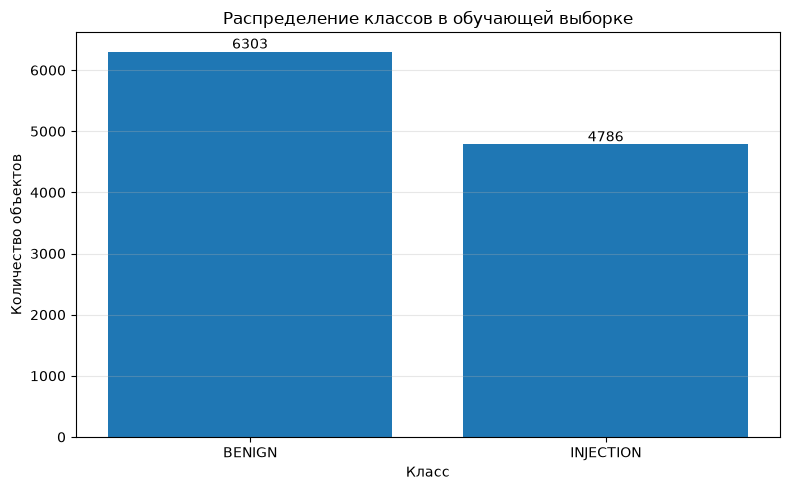

In [4]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["BENIGN", "INJECTION"],
    class_counts.values
)

plt.title("Распределение классов в обучающей выборке")
plt.xlabel("Класс")
plt.ylabel("Количество объектов")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 50,
        str(int(height)),
        ha="center"
    )

plt.tight_layout()
plt.show()

Статистика длины запросов:


count    11089.000000
mean        63.288123
std         43.752162
min          3.000000
25%         42.000000
50%         52.000000
75%         67.000000
max        627.000000
Name: text_length, dtype: float64

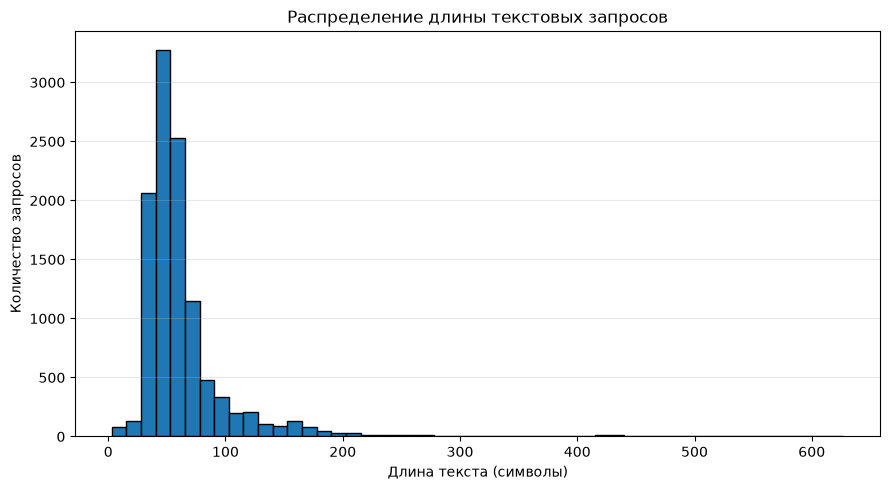

In [5]:
train["text_length"] = train["text"].fillna("").str.len()

print("Статистика длины запросов:")
display(train["text_length"].describe())

plt.figure(figsize=(9, 5))

plt.hist(
    train["text_length"],
    bins=50,
    edgecolor="black"
)

plt.title("Распределение длины текстовых запросов")
plt.xlabel("Длина текста (символы)")
plt.ylabel("Количество запросов")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Статистика длины по классам:


,count,mean,median,min,max
label,,,,,
0,6303,54.94,47.0,29,627
1,4786,74.29,63.0,3,615


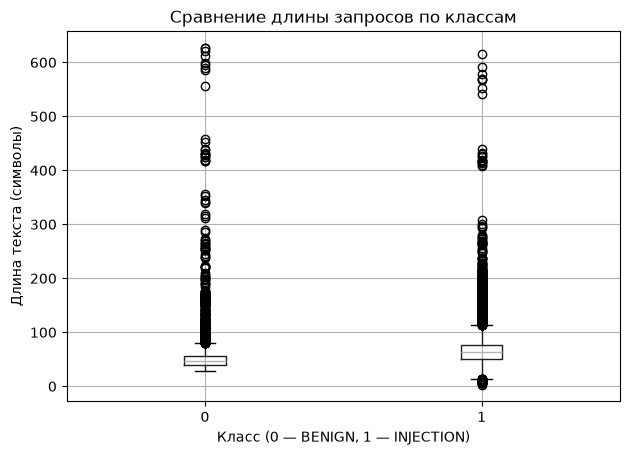

In [9]:
print("Статистика длины по классам:")

display(
    train.groupby("label")["text_length"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)


train.boxplot(
    column="text_length",
    by="label"
)

plt.title("Сравнение длины запросов по классам")
plt.suptitle("")
plt.xlabel("Класс (0 — BENIGN, 1 — INJECTION)")
plt.ylabel("Длина текста (символы)")

plt.tight_layout()
plt.show()

## Выводы по результатам исследования датасета

В ходе исследования был проведен первичный анализ датасета S-Labs/prompt-injection-dataset, предназначенного для решения задачи бинарной классификации текстовых запросов.

Датасет содержит 15 291 объект, распределенный между обучающей, валидационной и тестовой выборками. Каждый объект характеризуется текстовым содержимым и меткой класса.

Проверка качества обучающей выборки показала отсутствие пропущенных значений. При этом обнаружено 37 полных дубликатов строк, которые необходимо учитывать при дальнейшей подготовке данных.

Анализ распределения классов показал умеренный дисбаланс обучающей выборки: 56,84% объектов относятся к классу BENIGN, а 43,16% — к классу INJECTION. Разница составляет 1 517 объектов.

Исследование длины текстовых запросов показало, что средняя длина безопасного запроса составляет 54,94 символа, а prompt injection-запроса — 74,29 символа.

Таким образом, вредоносные запросы в рассматриваемом датасете в среднем длиннее безопасных. Однако распределения длины существенно пересекаются, что не позволяет использовать этот показатель как самостоятельный надежный критерий классификации.

Полученные результаты будут использованы при разработке ML-модели. Для оценки ее качества планируется применять Precision, Recall и F1-score, уделяя особое внимание обнаружению prompt injection-атак и анализу ложных отрицательных результатов.

Дополнительное внимание будет уделено проверке дубликатов между выборками, поскольку их наличие может приводить к утечке данных и завышению оценки качества модели.

In [8]:
from itertools import combinations

splits = {
    "Train": train,
    "Validation": validation,
    "Test": test
}

print("Проверка дубликатов внутри выборок:\n")

for name, df in splits.items():
    print(f"{name}:")
    print("Полные дубликаты:", df[["text", "label"]].duplicated().sum())
    print("Дубликаты текстов:", df["text"].duplicated().sum())
    print(
        "Тексты с разными метками:",
        (df.groupby("text")["label"].nunique() > 1).sum()
    )
    print()

print("Совпадения текстов между выборками:\n")

for (name1, df1), (name2, df2) in combinations(splits.items(), 2):
    texts1 = set(df1["text"].dropna())
    texts2 = set(df2["text"].dropna())

    overlap = texts1.intersection(texts2)

    print(f"{name1} / {name2}: {len(overlap)} совпадений")

Проверка дубликатов внутри выборок:

Train:
Полные дубликаты: 37
Дубликаты текстов: 38
Тексты с разными метками: 1

Validation:
Полные дубликаты: 0
Дубликаты текстов: 0
Тексты с разными метками: 0

Test:
Полные дубликаты: 0
Дубликаты текстов: 0
Тексты с разными метками: 0

Совпадения текстов между выборками:

Train / Validation: 4 совпадений
Train / Test: 0 совпадений
Validation / Test: 116 совпадений


## Анализ дубликатов и рисков утечки данных

Дополнительная проверка датасета выявила 37 полных дубликатов в обучающей выборке, 38 повторяющихся текстов и один текст, имеющий противоречивые метки классов.

В ходе сравнения выборок были обнаружены следующие пересечения:
- Train / Validation — 4 совпадающих текста;
- Train / Test — 0 совпадений;
- Validation / Test — 116 совпадений.

Наличие одинаковых текстов в обучающей и валидационной выборках, а также в валидационной и тестовой выборках создает риск утечки информации при разработке и оценке модели.

Особенно значимым является пересечение между Validation и Test, поскольку при подборе гиперпараметров на валидационной выборке может возникать косвенное влияние на итоговую оценку качества.

Для следующих этапов проекта рекомендуется сформировать очищенные выборки, исключить противоречивую разметку и проверить отсутствие пересечений между обучающими, валидационными и тестовыми данными.

Исходные CSV-файлы сохраняются без изменений. Их целостность контролируется при помощи SHA256.